Datasets baixados e carregados com sucesso
Utilizando dispositivo: cuda
CNNPersonalizada(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout_conv): Dropout2d(p=0.25, inplace=False)
  (dropout_fc): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


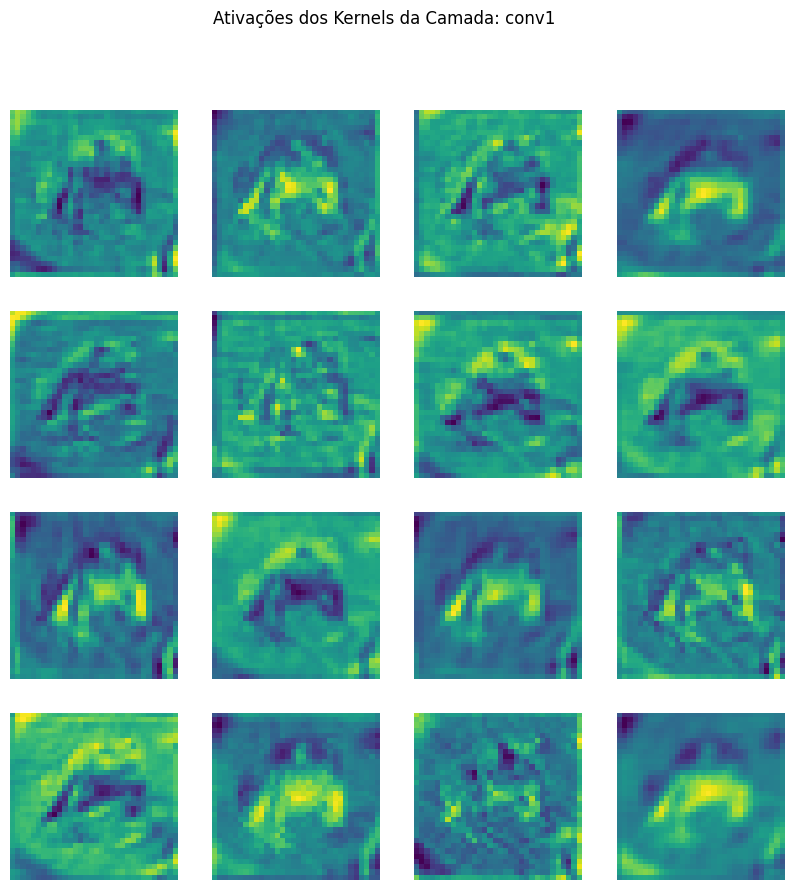

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Definir transformações e normalização
transformacao_mnist = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

transformacao_cifar = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Baixar os datasets MNIST e CIFAR-10
treino_mnist = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transformacao_mnist)
teste_mnist = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transformacao_mnist)

treino_cifar = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transformacao_cifar)
teste_cifar = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transformacao_cifar)

# Criar os DataLoaders (lotes de dados para o treinamento)
lote_tamanho = 64
carregador_treino_cifar = torch.utils.data.DataLoader(treino_cifar, batch_size=lote_tamanho, shuffle=True)
carregador_teste_cifar = torch.utils.data.DataLoader(teste_cifar, batch_size=lote_tamanho, shuffle=False)

print("Datasets baixados e carregados com sucesso")

class CNNPersonalizada(nn.Module):
    def __init__(self, num_classes=10, canais_entrada=3):
        super(CNNPersonalizada, self).__init__()
        self.conv1 = nn.Conv2d(canais_entrada, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.pool = nn.MaxPool2d(2, 2)
        self.dropout_conv = nn.Dropout2d(0.25)
        self.dropout_fc = nn.Dropout(0.5)

        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool(x)
        x = self.dropout_conv(x)

        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)
        x = self.dropout_conv(x)

        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout_fc(x)
        x = self.fc2(x)
        return x

def plotar_mapas_caracteristicas(modelo, imagem_exemplo, nome_camada='conv1'):
    modelo.eval()
    ativacao = {}

    # Função hook para capturar a saída da camada escolhida
    def obter_ativacao(nome):
        def hook(modelo, entrada, saida):
            ativacao[nome] = saida.detach()
        return hook

    # Registra o hook na camada desejada
    getattr(modelo, nome_camada).register_forward_hook(obter_ativacao(nome_camada))

    _ = modelo(imagem_exemplo.unsqueeze(0))

    atv = ativacao[nome_camada][0]

    # Plot dos primeiros 16 mapas de características (feature maps)
    fig, eixos = plt.subplots(4, 4, figsize=(10, 10))
    for i, ax in enumerate(eixos.flat):
        if i < atv.size(0):
            ax.imshow(atv[i].cpu(), cmap='viridis')
            ax.axis('off')
    plt.suptitle(f'Ativações dos Kernels da Camada: {nome_camada}')
    plt.show()

# Configurar dispositivo (GPU se disponível, senão CPU)
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Utilizando dispositivo: {dispositivo}")

# Instanciar a rede para o CIFAR-10 (3 canais, 10 classes)
modelo_cnn = CNNPersonalizada(num_classes=10, canais_entrada=3).to(dispositivo)
print(modelo_cnn)

# Testar o desafio de plotar ativações com uma imagem do CIFAR-10
imagem_teste, _ = treino_cifar[0]
plotar_mapas_caracteristicas(modelo_cnn, imagem_teste.to(dispositivo), nome_camada='conv1')

In [ ]:
import torch
import torch.optim as optim

total_epocas = 5
taxa_aprendizado = 0.001

# Função de perda e otimizador
criterio = nn.CrossEntropyLoss()
otimizador = optim.AdamW(modelo_cnn.parameters(), lr=taxa_aprendizado, weight_decay=0.01)

# Agendador de taxa de aprendizado
agendador = optim.lr_scheduler.StepLR(otimizador, step_size=3, gamma=0.1)

print("Configuração de treino inicializada com sucesso")

def treinar_epoca(modelo, carregador, criterio, otimizador, dispositivo):
    modelo.train()
    perda_acumulada = 0.0
    corretos = 0
    total_amostras = 0

    for entradas, rotulos in carregador:
        entradas, rotulos = entradas.to(dispositivo), rotulos.to(dispositivo)

        # Limpar gradientes
        otimizador.zero_grad()

        # Propagação para frente
        outputs = modelo(entradas)
        perda = criterio(outputs, rotulos)

        # Propagação para trás e otimização
        perda.backward()
        otimizador.step()

        # Acumular métricas
        perda_acumulada += perda.item() * entradas.size(0)
        _, predicoes = outputs.max(1)
        corretos += predicoes.eq(rotulos).sum().item()
        total_amostras += rotulos.size(0)

    perda_media = perda_acumulada / total_amostras
    acuracia = 100.0 * corretos / total_amostras
    return perda_media, acuracia


def avaliar_modelo(modelo, carregador, criterio, dispositivo):
    modelo.eval()
    perda_acumulada = 0.0
    corretos = 0
    total_amostras = 0

    with torch.no_grad():
        for entradas, rotulos in carregador:
            entradas, rotulos = entradas.to(dispositivo), rotulos.to(dispositivo)
            outputs = modelo(entradas)
            perda = criterio(outputs, rotulos)

            perda_acumulada += perda.item() * entradas.size(0)
            _, predicoes = outputs.max(1)
            corretos += predicoes.eq(rotulos).sum().item()
            total_amostras += rotulos.size(0)

    perda_media = perda_acumulada / total_amostras
    acuracia = 100.0 * corretos / total_amostras
    return perda_media, acuracia

print("Iniciando o treinamento")

for epoca in range(total_epocas):
    # Treinar uma época
    perda_treino, acc_treino = treinar_epoca(modelo_cnn, carregador_treino_cifar, criterio, otimizador, dispositivo)

    # Avaliar no conjunto de teste
    perda_teste, acc_teste = avaliar_modelo(modelo_cnn, carregador_teste_cifar, criterio, dispositivo)

    # Atualizar o agendador de taxa de aprendizado
    agendador.step()

    print(f"Época [{epoca+1}/{total_epocas}] | Perda Treino: {perda_treino:.4f} - Acc Treino: {acc_treino:.2f}% | Perda Teste: {perda_teste:.4f} - Acc Teste: {acc_teste:.2f}%")

print("Treinamento concluído com sucesso")

Configuração de treino inicializada com sucesso
Iniciando o treinamento
Época [1/5] | Perda Treino: 1.8495 - Acc Treino: 29.95% | Perda Teste: 1.4782 - Acc Teste: 47.79%
Época [2/5] | Perda Treino: 1.6580 - Acc Treino: 37.72% | Perda Teste: 1.3540 - Acc Teste: 53.64%
Época [3/5] | Perda Treino: 1.5844 - Acc Treino: 39.92% | Perda Teste: 1.2969 - Acc Teste: 56.35%
Época [4/5] | Perda Treino: 1.5020 - Acc Treino: 43.35% | Perda Teste: 1.2288 - Acc Teste: 58.62%
Época [5/5] | Perda Treino: 1.4849 - Acc Treino: 43.81% | Perda Teste: 1.2074 - Acc Teste: 59.13%
Treinamento concluído com sucesso


In [ ]:
import torchvision.models as modelos

# Carregar a arquitetura ResNet18 com os pesos pré-treinados padrão
pesos_iniciais = modelos.ResNet18_Weights.DEFAULT
rede_resnet = modelos.resnet18(weights=pesos_iniciais)

# Ajustar a camada final de classificação para as 10 classes do CIFAR-10
tamanho_entrada_fc = rede_resnet.fc.in_features
rede_resnet.fc = torch.nn.Linear(tamanho_entrada_fc, 10)

# Enviar a rede pré-treinada para a mesma GPU ou dispositivo utilizado anteriormente
rede_resnet = rede_resnet.to(dispositivo)

print("Rede ResNet18 pré-treinada carregada e adaptada com sucesso")

# Configurar parâmetros específicos para o ajuste fino (fine-tuning)
epocas_resnet = 3
otimizador_resnet = torch.optim.AdamW(rede_resnet.parameters(), lr=1e-4, weight_decay=0.01)

print("Iniciando o ajuste fino da ResNet18")

for contador_epoca in range(epocas_resnet):
    # Reutilizando as mesmas funções de treino e avaliação já criadas
    perda_treino_rn, acuracia_treino_rn = treinar_epoca(rede_resnet, carregador_treino_cifar, criterio, otimizador_resnet, dispositivo)
    perda_teste_rn, acuracia_teste_rn = avaliar_modelo(rede_resnet, carregador_teste_cifar, criterio, dispositivo)

    print(f"ResNet Época [{contador_epoca+1}/{epocas_resnet}] | Perda Treino: {perda_treino_rn:.4f} - Acc Treino: {acuracia_treino_rn:.2f}% | Perda Teste: {perda_teste_rn:.4f} - Acc Teste: {acuracia_teste_rn:.2f}%")

print("Fine-tuning da ResNet18 concluído com sucesso")

Rede ResNet18 pré-treinada carregada e adaptada com sucesso
Iniciando o ajuste fino da ResNet18
ResNet Época [1/3] | Perda Treino: 0.9883 - Acc Treino: 66.12% | Perda Teste: 0.6779 - Acc Teste: 76.78%
ResNet Época [2/3] | Perda Treino: 0.5752 - Acc Treino: 80.08% | Perda Teste: 0.5879 - Acc Teste: 80.12%
ResNet Época [3/3] | Perda Treino: 0.4086 - Acc Treino: 85.70% | Perda Teste: 0.5715 - Acc Teste: 80.89%
Fine-tuning da ResNet18 concluído com sucesso


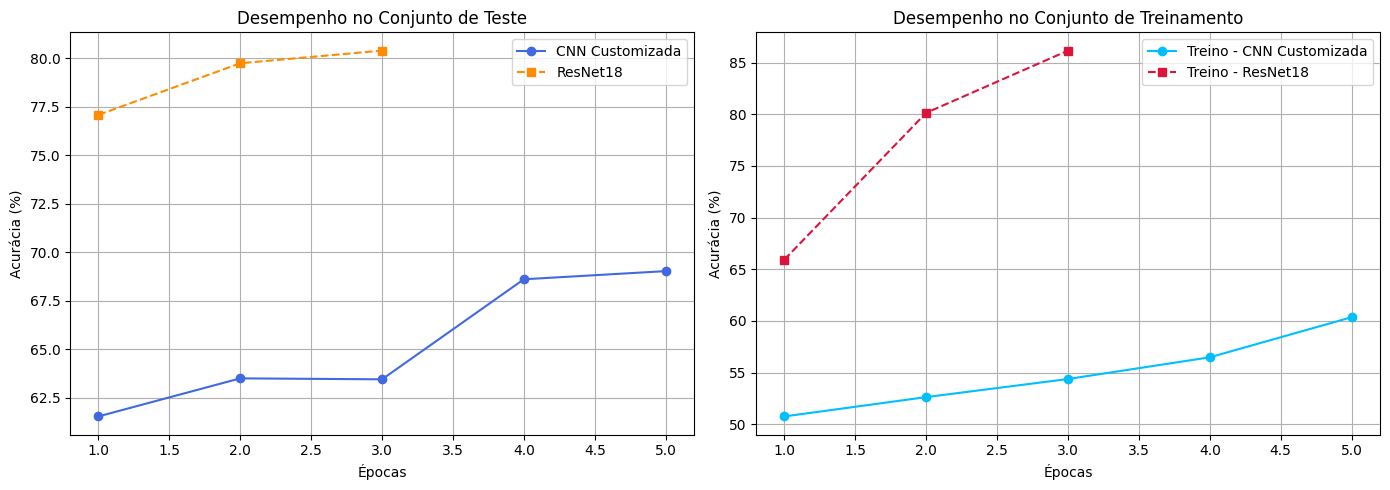

In [ ]:
import matplotlib.pyplot as plt

# Coleta de dados dos modelos treinados
ciclos_customizados = [1, 2, 3, 4, 5]
taxa_acerto_treino_custom = [50.76, 52.63, 54.38, 56.48, 60.36]
taxa_acerto_teste_custom = [61.55, 63.51, 63.46, 68.61, 69.03]

ciclos_resnet = [1, 2, 3]
taxa_acerto_treino_rn = [65.93, 80.13, 86.15]
taxa_acerto_teste_rn = [77.07, 79.73, 80.38]

# Construção da visualização gráfica
painel, (area_teste, area_treino) = plt.subplots(1, 2, figsize=(14, 5))

# Plotagem do desempenho no conjunto de teste
area_teste.plot(ciclos_customizados, taxa_acerto_teste_custom, marker='o', linestyle='-', color='royalblue', label='CNN Customizada')
area_teste.plot(ciclos_resnet, taxa_acerto_teste_rn, marker='s', linestyle='--', color='darkorange', label='ResNet18')
area_teste.set_title('Desempenho no Conjunto de Teste')
area_teste.set_xlabel('Épocas')
area_teste.set_ylabel('Acurácia (%)')
area_teste.grid(True)
area_teste.legend()

# Plotagem do desempenho no conjunto de treino
area_treino.plot(ciclos_customizados, taxa_acerto_treino_custom, marker='o', linestyle='-', color='deepskyblue', label='Treino - CNN Customizada')
area_treino.plot(ciclos_resnet, taxa_acerto_treino_rn, marker='s', linestyle='--', color='crimson', label='Treino - ResNet18')
area_treino.set_title('Desempenho no Conjunto de Treinamento')
area_treino.set_xlabel('Épocas')
area_treino.set_ylabel('Acurácia (%)')
area_treino.grid(True)
area_treino.legend()

plt.tight_layout()
plt.show()

Iniciando o estudo de ablação
Treinando modelo completo (com dropout)
Treinando modelo ablado (sem dropout)


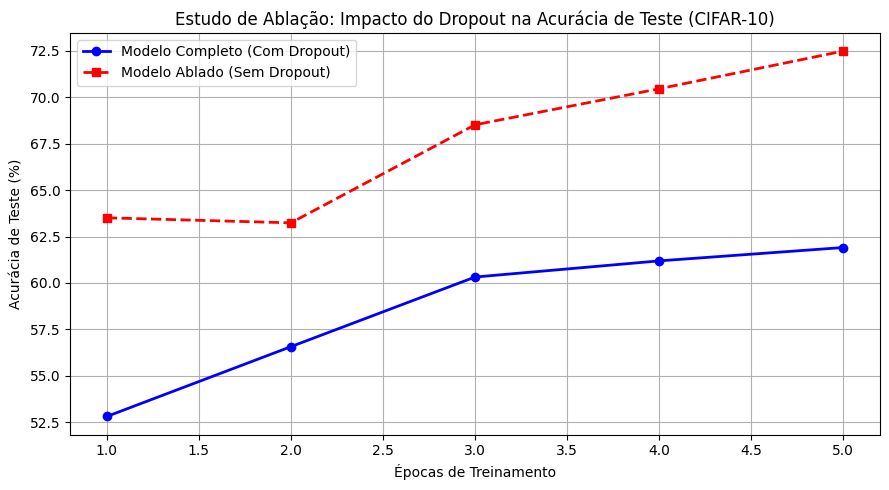

Estudo de ablação concluído e gráfico salvo com sucesso


In [ ]:
print("Iniciando o estudo de ablação")


class CNNComAblacao(nn.Module):
    def __init__(self, num_classes=10, canais_entrada=3, usar_dropout=True):
        super().__init__()
        self.usar_dropout = usar_dropout

        # Blocos convolucionais
        self.camada_conv1 = nn.Conv2d(canais_entrada, 32, kernel_size=3, padding=1)
        self.normalizacao1 = nn.BatchNorm2d(32)
        self.camada_conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.normalizacao2 = nn.BatchNorm2d(64)
        self.agrupamento = nn.MaxPool2d(2, 2)

        # Componente alvo da ablação: Dropout (ou Identity quando desativado)
        if usar_dropout:
            self.descarte_conv = nn.Dropout2d(0.25)
            self.descarte_densa = nn.Dropout(0.5)
        else:
            self.descarte_conv = nn.Identity()
            self.descarte_densa = nn.Identity()

        # Camadas densas
        self.camada_densa1 = nn.Linear(64 * 8 * 8, 128)
        self.camada_densa2 = nn.Linear(128, num_classes)

    def forward(self, entrada):
        saida = F.relu(self.normalizacao1(self.camada_conv1(entrada)))
        saida = self.agrupamento(saida)
        saida = self.descarte_conv(saida)

        saida = F.relu(self.normalizacao2(self.camada_conv2(saida)))
        saida = self.agrupamento(saida)
        saida = self.descarte_conv(saida)

        saida = saida.view(saida.size(0), -1)
        saida = F.relu(self.camada_densa1(saida))
        saida = self.descarte_densa(saida)
        saida = self.camada_densa2(saida)
        return saida


def treinar_e_registrar_acuracia(descricao, usar_dropout, num_epocas=5):
    print(descricao)
    modelo = CNNComAblacao(num_classes=10, canais_entrada=3, usar_dropout=usar_dropout).to(dispositivo)
    otimizador = optim.AdamW(modelo.parameters(), lr=0.001, weight_decay=0.01)

    historico_acuracia = []
    for _ in range(num_epocas):
        treinar_epoca(modelo, carregador_treino_cifar, criterio, otimizador, dispositivo)
        _, acuracia = avaliar_modelo(modelo, carregador_teste_cifar, criterio, dispositivo)
        historico_acuracia.append(acuracia)
    return historico_acuracia


NUM_EPOCAS = 5

# Modelo completo (com Dropout) e modelo ablado (sem Dropout)
acuracia_modelo_completo = treinar_e_registrar_acuracia(
    "Treinando modelo completo (com dropout)", usar_dropout=True, num_epocas=NUM_EPOCAS
)
acuracia_modelo_ablado = treinar_e_registrar_acuracia(
    "Treinando modelo ablado (sem dropout)", usar_dropout=False, num_epocas=NUM_EPOCAS
)

# Gráfico de influência do componente
eixo_epocas = range(1, NUM_EPOCAS + 1)

plt.figure(figsize=(9, 5))
plt.plot(eixo_epocas, acuracia_modelo_completo, marker='o', linestyle='-',
         color='blue', linewidth=2, label='Modelo Completo (Com Dropout)')
plt.plot(eixo_epocas, acuracia_modelo_ablado, marker='s', linestyle='--',
         color='red', linewidth=2, label='Modelo Ablado (Sem Dropout)')
plt.title('Estudo de Ablação: Impacto do Dropout na Acurácia de Teste (CIFAR-10)')
plt.xlabel('Épocas de Treinamento')
plt.ylabel('Acurácia de Teste (%)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('grafico_estudo_ablacao.png')
plt.show()

print("Estudo de ablação concluído e gráfico salvo com sucesso")